# ML Assignment 2 Q3: Measuring Bias and Variance
**Amrit Kumar Giri (M26ECC001)**

## Imports and fixed data split

In [1]:
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from joblib import Parallel, delayed

SEED = 26001
R = 30
N_JOBS = 4
DATA_DIR = Path('data')
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)

split_path = DATA_DIR / 'saved_split.npz'
if not split_path.exists():
    raise FileNotFoundError('Missing data/saved_split.npz — copy it from your original Q1 project.')

faces = fetch_olivetti_faces(shuffle=False)
X, y = faces.data, faces.target
saved = np.load(split_path)
assert int(saved['seed']) == SEED
train_idx, val_idx, test_idx = (saved[k] for k in ['train_idx','val_idx','test_idx'])
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
classes = np.unique(y)
K = len(classes)
assert X_train.shape == (240, 4096) and X_test.shape == (80, 4096)
assert all(np.sum(y_train == c) == 6 for c in classes)
print('Training:', X_train.shape, '| Validation:', X_val.shape, '| Fixed clean test:', X_test.shape)
print('Seed:', SEED, '| Number of refits:', R, '| CPU workers:', N_JOBS)

Training: (240, 4096) | Validation: (80, 4096) | Fixed clean test: (80, 4096)
Seed: 26001 | Number of refits: 30 | CPU workers: 4


## Settings already selected in Q1 and Q2

In [2]:
tree_csv = RESULT_DIR / 'q1a_tree_configs.csv'
bag_csv = RESULT_DIR / 'q1b_bagging_accuracy.csv'
boost_json = RESULT_DIR / 'q2_selected_config.json'
for p in [tree_csv, bag_csv, boost_json]:
    if not p.exists():
        raise FileNotFoundError(f'Missing {p}. Keep the Q1/Q2 results in the same results folder.')

tree_table = pd.read_csv(tree_csv)
tree_winner = tree_table.sort_values(
    ['val_acc', 'n_leaves', 'min_leaf'], ascending=[False, True, False]
).iloc[0]
TREE_DEPTH = None if pd.isna(tree_winner['depth']) else int(tree_winner['depth'])
MIN_LEAF = int(tree_winner['min_leaf'])

bag_table = pd.read_csv(bag_csv)
BAG_SIZE = int(bag_table.sort_values(['val_acc', 'B'], ascending=[False, True]).iloc[0]['B'])

with open(boost_json) as f:
    boost_config = json.load(f)
BOOST_DEPTH = int(boost_config['max_depth'])
BOOST_ROUNDS = int(boost_config['n_rounds'])

print('Selected single-tree settings:', TREE_DEPTH, 'depth; min leaf', MIN_LEAF)
print('Selected bagging ensemble:', BAG_SIZE, 'trees, using those tree settings')
print('Selected SAMME:', BOOST_DEPTH, 'depth;', BOOST_ROUNDS, 'rounds')
assert TREE_DEPTH is None or TREE_DEPTH >= 1
assert BAG_SIZE >= 1 and BOOST_ROUNDS >= 1

Selected single-tree settings: None depth; min leaf 4
Selected bagging ensemble: 50 trees, using those tree settings
Selected SAMME: 3 depth; 100 rounds


## Make 30 resampled training sets

In [3]:
refit_file = DATA_DIR / 'q3_refit_indices.npz'
if refit_file.exists():
    refit_indices = np.load(refit_file)['indices']
    print('Loaded existing resampling indices.')
else:
    sample_rng = np.random.default_rng(SEED + 300)
    all_refits = []
    for r in range(R):
        sampled = []
        for c in classes:
            original_six = np.flatnonzero(y_train == c)
            sampled.extend(sample_rng.choice(original_six, size=6, replace=True))
        all_refits.append(sampled)
    refit_indices = np.asarray(all_refits, dtype=int)
    np.savez(refit_file, indices=refit_indices, seed=SEED)
assert refit_indices.shape == (30, 240)
for sample in refit_indices:
    assert all(np.sum(y_train[sample] == c) == 6 for c in classes)
print('Resamples:', refit_indices.shape)
print('Distinct faces in first resample:', len(np.unique(refit_indices[0])))

Resamples: (30, 240)
Distinct faces in first resample: 158


## Helpers for predictions and measured bias–variance

In [5]:
def class_vectors(labels):
    output = np.zeros((len(labels), K), dtype=np.float32)
    output[np.arange(len(labels)), labels.astype(int)] = 1.0
    return output

TARGET = class_vectors(y_test)

def tree_vectors(model, images):
    return class_vectors(model.predict(images))

def vote_vectors(trees, images):
    votes = np.zeros((len(images), K), dtype=np.float32)
    rows = np.arange(len(images))
    for tree in trees:
        predictions = tree.predict(images).astype(int)
        votes[rows, predictions] += 1
    return votes / len(trees)

def measure_bias_variance(prediction_vectors):
    p = np.asarray(prediction_vectors, dtype=np.float64)
    assert p.shape == (R, len(y_test), K)
    assert np.allclose(p.sum(axis=2), 1, atol=1e-5)
    mean_prediction = p.mean(axis=0)
    bias_squared = np.mean(np.sum((mean_prediction - TARGET)**2, axis=1))
    variance = np.mean(np.sum((p - mean_prediction[None])**2, axis=2))
    predicted_class = p.argmax(axis=2)
    accuracies = np.mean(predicted_class == y_test[None, :], axis=1)
    return {
        'bias_squared': float(bias_squared),
        'variance': float(variance),
        'mean_test_accuracy': float(accuracies.mean()),
        'std_test_accuracy': float(accuracies.std(ddof=1)),
        'accuracies': accuracies,
    }

check = np.repeat(TARGET[None], R, axis=0)
assert measure_bias_variance(check)['variance'] < 1e-12
print('Bias–variance calculation checked.')

Bias–variance calculation checked.


## SAMME boosting from scratch (same update rule as Q2)

In [6]:
def fit_samme(images, labels, depth, rounds, seed):
    sample_weights = np.full(len(labels), 1.0 / len(labels))
    rng_local = np.random.default_rng(seed)
    fitted_trees, alphas = [], []
    n_classes = len(np.unique(labels))

    for t in range(rounds):
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=int(rng_local.integers(0, 2**31 - 1))
        )
        tree.fit(images, labels, sample_weight=sample_weights)
        wrong = tree.predict(images) != labels
        error = float(sample_weights[wrong].sum())

        if error <= 1e-15:
            alpha = float(np.log((1 - 1e-15)/1e-15) + np.log(n_classes - 1))
            fitted_trees.append(tree)
            alphas.append(alpha)
            break
        if not np.isfinite(error) or error >= 1 - 1 / n_classes:
            break

        alpha = float(np.log((1 - error)/error) + np.log(n_classes - 1))
        sample_weights *= np.exp(alpha * wrong)
        sample_weights /= sample_weights.sum()
        fitted_trees.append(tree)
        alphas.append(alpha)

    if not fitted_trees:
        raise RuntimeError('SAMME could not fit a valid learner.')
    return fitted_trees, np.asarray(alphas)

def boost_vectors(trees, alphas, images):
    scores = np.zeros((len(images), K), dtype=np.float32)
    rows = np.arange(len(images))
    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(images).astype(int)
        scores[rows, predictions] += alpha
    return scores / scores.sum(axis=1, keepdims=True)

print('SAMME helpers ready.')

SAMME helpers ready.


## Training helpers (reproducible and resumable)

In [7]:
def fit_single(images, labels, depth, leaf_size, seed):
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf_size,
                                   random_state=seed)
    model.fit(images, labels)
    return model

def fit_bagged(images, labels, depth, leaf_size, count, seed):
    n = len(labels)
    boot_rng = np.random.default_rng(seed)
    boot_indices = [boot_rng.integers(0, n, n) for _ in range(count)]
    seeds = np.random.default_rng(seed + 1).integers(0, 2**31-1, size=count)

    def fit_one(t):
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf_size,
                                       random_state=int(seeds[t]))
        idx = boot_indices[t]
        model.fit(images[idx], labels[idx])
        return model

    return Parallel(n_jobs=N_JOBS, backend='threading')(
        delayed(fit_one)(t) for t in range(count)
    )

def run_refits(name, model_type, depth, leaf_size=None, count=None):
    filename = RESULT_DIR / f'q3_predictions_{name}.npz'
    if filename.exists():
        saved_results = np.load(filename)
        pred = saved_results['vectors']
        assert pred.shape == (R, len(y_test), K)
        print(f'{name}: loaded 30 saved refits')
        return pred

    all_predictions = np.empty((R, len(y_test), K), dtype=np.float32)
    partial_file = filename.with_name(filename.stem + '_partial.npz')
    start_at = 0
    if partial_file.exists():
        partial = np.load(partial_file)
        start_at = int(partial['completed'])
        all_predictions[:start_at] = partial['vectors']
        print(f'{name}: resuming from refit {start_at + 1}')
    start = time.perf_counter()
    for r in range(start_at, R):
        sample = refit_indices[r]
        images, labels = X_train[sample], y_train[sample]
        seed = SEED + 10000 + r * 1009

        if model_type == 'single':
            model = fit_single(images, labels, depth, leaf_size, seed)
            p = tree_vectors(model, X_test)
        elif model_type == 'bagging':
            trees = fit_bagged(images, labels, depth, leaf_size, count, seed)
            p = vote_vectors(trees, X_test)
        elif model_type == 'boosting':
            trees, alphas = fit_samme(images, labels, depth, count, seed)
            p = boost_vectors(trees, alphas, X_test)
        else:
            raise ValueError('Unsupported model type')

        all_predictions[r] = p
        np.savez_compressed(partial_file,
                            vectors=all_predictions[:r+1], completed=r+1)
        if (r + 1) % 5 == 0 or r == 0:
            print(f'{name}: {r+1}/{R} refits finished, {time.perf_counter()-start:.1f}s')

    np.savez_compressed(filename, vectors=all_predictions)
    partial_file.unlink(missing_ok=True)
    return all_predictions

## Q3(a) Selected single tree, bagging and boosting

In [8]:
baseline_specs = [
    ('Single Tree', 'single', TREE_DEPTH, MIN_LEAF, None, 'q3_selected_tree'),
    ('Bagging', 'bagging', TREE_DEPTH, MIN_LEAF, BAG_SIZE, 'q3_selected_bagging'),
    ('Boosting', 'boosting', BOOST_DEPTH, None, BOOST_ROUNDS, 'q3_selected_boosting')
]

selected_rows = []
for label, model_type, depth, leaf, count, filename in baseline_specs:
    predictions = run_refits(filename, model_type, depth, leaf, count)
    stats = measure_bias_variance(predictions)
    selected_rows.append({
        'model': label,
        'bias_squared': stats['bias_squared'],
        'variance': stats['variance'],
        'mean_test_accuracy': stats['mean_test_accuracy'],
        'std_test_accuracy': stats['std_test_accuracy']
    })

selected_results = pd.DataFrame(selected_rows)
display(selected_results.round(5))
selected_results.to_csv(RESULT_DIR / 'q3a_selected_bias_variance.csv', index=False)

q3_selected_tree: 1/30 refits finished, 2.5s
q3_selected_tree: 5/30 refits finished, 12.3s
q3_selected_tree: 10/30 refits finished, 24.1s
q3_selected_tree: 15/30 refits finished, 36.1s
q3_selected_tree: 20/30 refits finished, 48.7s
q3_selected_tree: 25/30 refits finished, 61.3s
q3_selected_tree: 30/30 refits finished, 74.4s
q3_selected_bagging: 1/30 refits finished, 22.8s
q3_selected_bagging: 5/30 refits finished, 115.0s
q3_selected_bagging: 10/30 refits finished, 229.6s
q3_selected_bagging: 15/30 refits finished, 343.6s
q3_selected_bagging: 20/30 refits finished, 460.7s
q3_selected_bagging: 25/30 refits finished, 577.3s
q3_selected_bagging: 30/30 refits finished, 697.9s
q3_selected_boosting: 1/30 refits finished, 38.5s
q3_selected_boosting: 5/30 refits finished, 189.8s
q3_selected_boosting: 10/30 refits finished, 385.3s
q3_selected_boosting: 15/30 refits finished, 572.1s
q3_selected_boosting: 20/30 refits finished, 760.5s
q3_selected_boosting: 25/30 refits finished, 946.1s
q3_selected

,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,Single Tree,0.40617,0.64467,0.47458,0.04984
1,Bagging,0.53494,0.03102,0.71333,0.03565
2,Boosting,0.91052,0.01465,0.23208,0.07526


## Q3(a) Plot the measured bias and variance

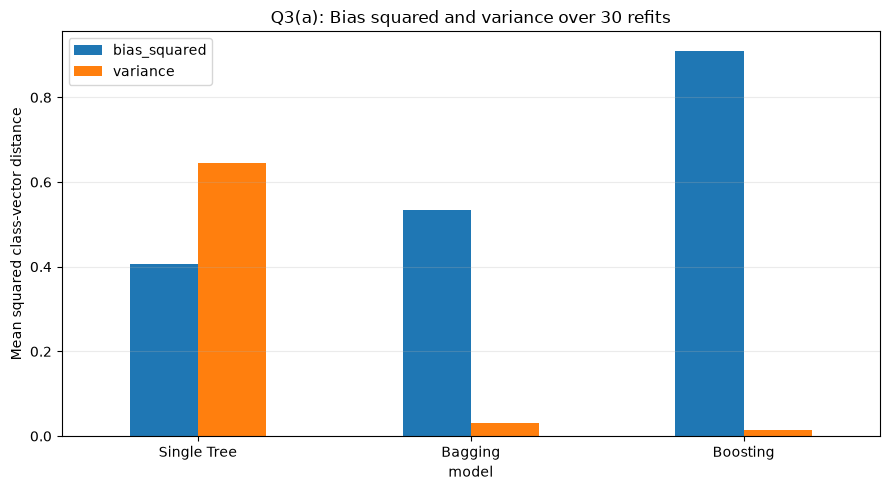

In [9]:
ax = selected_results.set_index('model')[['bias_squared', 'variance']].plot(
    kind='bar', figsize=(9,5), rot=0)
ax.set_title('Q3(a): Bias squared and variance over 30 refits')
ax.set_ylabel('Mean squared class-vector distance')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q3a_bias_variance.png', dpi=300)
plt.show()

## Q3(b) Depth experiment

In [10]:
DEPTHS_Q3 = [2, 16, None] if TREE_DEPTH is None else [2, TREE_DEPTH, 32]
if len(set(DEPTHS_Q3)) != 3:
    raise ValueError('Choose three distinct depths while keeping the selected depth unchanged.')

depth_rows = []
for depth in DEPTHS_Q3:
    label = 'unrestricted' if depth is None else str(depth)
    for model_type, count in [('single', None), ('bagging', 100)]:
        filename = f'q3_depth_{label}_{model_type}'
        p = run_refits(filename, model_type, depth, MIN_LEAF, count)
        stats = measure_bias_variance(p)
        depth_rows.append({
            'depth': label,
            'type': model_type,
            'bias_squared': stats['bias_squared'],
            'variance': stats['variance'],
            'mean_test_accuracy': stats['mean_test_accuracy'],
            'std_test_accuracy': stats['std_test_accuracy']
        })

depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(5))
depth_results.to_csv(RESULT_DIR / 'q3b_depth_bias_variance.csv', index=False)

q3_depth_2_single: 1/30 refits finished, 0.3s
q3_depth_2_single: 5/30 refits finished, 1.3s
q3_depth_2_single: 10/30 refits finished, 2.6s
q3_depth_2_single: 15/30 refits finished, 3.9s
q3_depth_2_single: 20/30 refits finished, 5.3s
q3_depth_2_single: 25/30 refits finished, 6.8s
q3_depth_2_single: 30/30 refits finished, 8.1s
q3_depth_2_bagging: 1/30 refits finished, 5.9s
q3_depth_2_bagging: 5/30 refits finished, 29.8s
q3_depth_2_bagging: 10/30 refits finished, 60.5s
q3_depth_2_bagging: 15/30 refits finished, 90.8s
q3_depth_2_bagging: 20/30 refits finished, 121.7s
q3_depth_2_bagging: 25/30 refits finished, 152.0s
q3_depth_2_bagging: 30/30 refits finished, 182.6s
q3_depth_16_single: 1/30 refits finished, 1.7s
q3_depth_16_single: 5/30 refits finished, 8.3s
q3_depth_16_single: 10/30 refits finished, 16.3s
q3_depth_16_single: 15/30 refits finished, 24.7s
q3_depth_16_single: 20/30 refits finished, 33.0s
q3_depth_16_single: 25/30 refits finished, 41.2s
q3_depth_16_single: 30/30 refits finishe

,depth,type,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,2,single,1.81039,0.07378,0.05792,0.01449
1,2,bagging,0.93146,0.01152,0.14292,0.06234
2,16,single,0.96503,0.48747,0.27375,0.03719
3,16,bagging,0.67739,0.01972,0.60875,0.03687
4,unrestricted,single,0.40617,0.64467,0.47458,0.04984
5,unrestricted,bagging,0.53680,0.02322,0.72875,0.03099


## Q3(b) Visualize accuracy, bias² and variance by depth

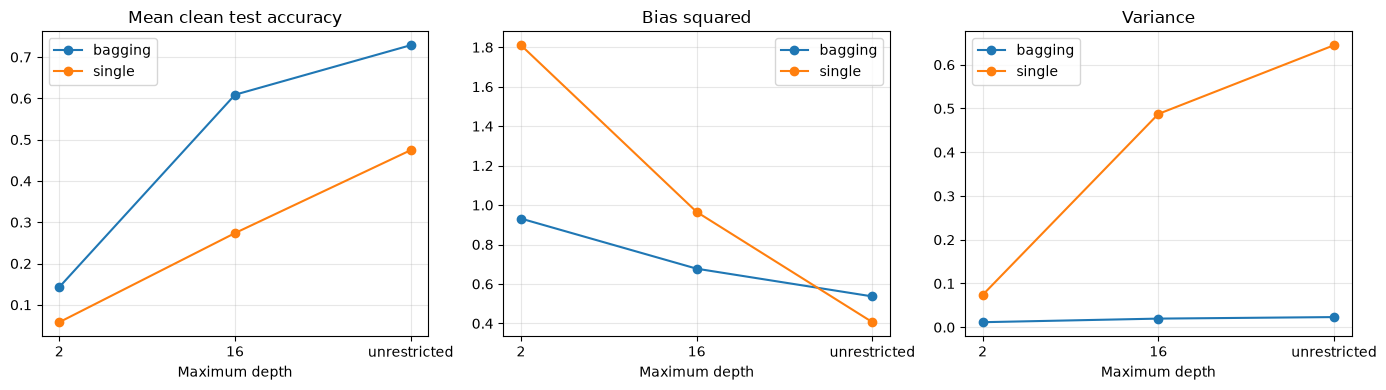

In [11]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for column, ax, heading in zip(
    ['mean_test_accuracy','bias_squared','variance'], axes,
    ['Mean clean test accuracy','Bias squared','Variance']
):
    for kind, sub in depth_results.groupby('type'):
        ax.plot(sub['depth'], sub[column], marker='o', label=kind)
    ax.set_title(heading)
    ax.set_xlabel('Maximum depth')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q3b_depth_comparison.png', dpi=300)
plt.show()

## Q3(c) Leaf occupancy, pairwise disagreement and bagging improvement

In [12]:
def mean_pairwise_disagreement(trees, images):
    B = len(trees)
    if B < 2:
        return np.nan
    counts = np.zeros((len(images), K), dtype=np.int32)
    rows = np.arange(len(images))
    for tree in trees:
        counts[rows, tree.predict(images).astype(int)] += 1
    total_pairs = B * (B-1)/2
    same_pairs = np.sum(counts * (counts - 1) / 2, axis=1)
    return float(np.mean(1 - same_pairs/total_pairs))

analysis_rows = []
for depth in DEPTHS_Q3:
    depth_label = 'unrestricted' if depth is None else str(depth)
    one = fit_single(X_train, y_train, depth, MIN_LEAF, SEED)
    _, occupancies = np.unique(one.apply(X_train), return_counts=True)
    trees100 = fit_bagged(X_train, y_train, depth, MIN_LEAF, 100, SEED + 1)
    single_acc = float(depth_results.query('depth == @depth_label and type == "single"')['mean_test_accuracy'].iloc[0])
    bag_acc = float(depth_results.query('depth == @depth_label and type == "bagging"')['mean_test_accuracy'].iloc[0])
    analysis_rows.append({
        'depth': depth_label,
        'number_of_leaves': one.get_n_leaves(),
        'mean_leaf_occupancy': float(occupancies.mean()),
        'singleton_fraction': float(np.mean(occupancies == 1)),
        'tree_disagreement': mean_pairwise_disagreement(trees100, X_val),
        'single_mean_accuracy': single_acc,
        'bag100_mean_accuracy': bag_acc,
        'bagging_gain_pp': 100 * (bag_acc - single_acc)
    })

q3c_results = pd.DataFrame(analysis_rows)
display(q3c_results.round(5))
q3c_results.to_csv(RESULT_DIR / 'q3c_depth_evidence.csv', index=False)

largest_gain = q3c_results.loc[q3c_results['bagging_gain_pp'].idxmax()]
print('Largest measured bagging improvement at depth:', largest_gain['depth'])
print('Improvement (percentage points):', round(float(largest_gain['bagging_gain_pp']), 2))

,depth,number_of_leaves,mean_leaf_occupancy,singleton_fraction,tree_disagreement,single_mean_accuracy,bag100_mean_accuracy,bagging_gain_pp
0,2,3,80.00000,0.0,0.96311,0.05792,0.14292,8.50000
1,16,18,13.33333,0.0,0.87571,0.27375,0.60875,33.50000
2,unrestricted,41,5.85366,0.0,0.80865,0.47458,0.72875,25.41667


Largest measured bagging improvement at depth: 16
Improvement (percentage points): 33.5


## Q3(d) One final comparison table

In [13]:
q2_final_path = RESULT_DIR / 'q2d_final_comparison.csv'
if not q2_final_path.exists():
    raise FileNotFoundError('Missing results/q2d_final_comparison.csv; run Q2(d) first.')
q2_final = pd.read_csv(q2_final_path)
q2_final['model'] = q2_final['model'].replace({'Single Tree': 'Single Tree', 'Bagging': 'Bagging', 'Boosting': 'Boosting'})
q3_final = q2_final[['model', 'clean_accuracy', 'masked_accuracy']].merge(
    selected_results[['model','bias_squared','variance']], on='model', how='inner'
)
assert len(q3_final) == 3, 'Check the model labels in Q2(d) and Q3(a).'
q3_final['masking_drop_pp'] = 100*(q3_final['clean_accuracy'] - q3_final['masked_accuracy'])
display(q3_final.round(5))
q3_final.to_csv(RESULT_DIR / 'q3d_final_summary.csv', index=False)

most_stable = q3_final.loc[q3_final['variance'].idxmin(), 'model']
most_sensitive = q3_final.loc[q3_final['masking_drop_pp'].idxmax(), 'model']
best_test = q3_final.loc[q3_final['clean_accuracy'].idxmax(), 'model']
print('Lowest measured variance:', most_stable)
print('Largest masking accuracy drop:', most_sensitive)
print('Highest clean test accuracy:', best_test)
print('Lowest variance has highest clean accuracy:', most_stable == best_test)

,model,clean_accuracy,masked_accuracy,bias_squared,variance,masking_drop_pp
0,Single Tree,0.5375,0.3500,0.40617,0.64467,18.75
1,Bagging,0.8000,0.6125,0.53494,0.03102,18.75
2,Boosting,0.5000,0.4625,0.91052,0.01465,3.75


Lowest measured variance: Boosting
Largest masking accuracy drop: Single Tree
Highest clean test accuracy: Bagging
Lowest variance has highest clean accuracy: False


## Q3(d) Final figure

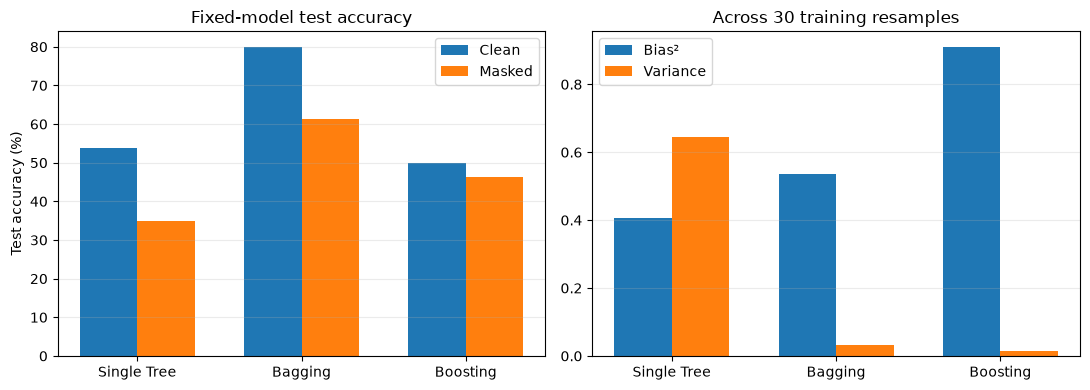

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
names = q3_final['model'].tolist()
x = np.arange(len(names))
w = 0.35
axes[0].bar(x-w/2, 100*q3_final['clean_accuracy'], width=w, label='Clean')
axes[0].bar(x+w/2, 100*q3_final['masked_accuracy'], width=w, label='Masked')
axes[0].set_xticks(x, names)
axes[0].set_ylabel('Test accuracy (%)')
axes[0].set_title('Fixed-model test accuracy')
axes[0].legend()
axes[1].bar(x-w/2, q3_final['bias_squared'], width=w, label='Bias²')
axes[1].bar(x+w/2, q3_final['variance'], width=w, label='Variance')
axes[1].set_xticks(x, names)
axes[1].set_title('Across 30 training resamples')
axes[1].legend()
for ax in axes: ax.grid(axis='y',alpha=.25)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'q3d_final_summary.png',dpi=300)
plt.show()